In [91]:
import numpy as np
import pandas as pd
import os
import torch
import matplotlib.pyplot as plt
import random
from functools import partial
import time
from torch.utils.data import Dataset, DataLoader
from torch.utils.data import TensorDataset
from tqdm.notebook import tqdm

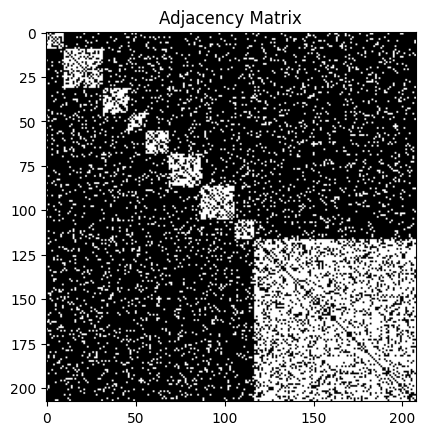

In [92]:
# Construct an adjacency matrix from the stochastic block model
p_intra = 0.75
p_inter = 0.1
cluster_sizes = [10, 22, 14, 10, 13, 18, 19, 11, 91] #[50, 20, 30]
N = sum(cluster_sizes)

A = np.zeros((N, N), dtype=float)
cum_cluster_sizes = np.cumsum([0] + cluster_sizes)

# Add intra-cluster edges
for i in np.arange(1, len(cum_cluster_sizes)):
    A[cum_cluster_sizes[i-1]:cum_cluster_sizes[i], cum_cluster_sizes[i-1]:cum_cluster_sizes[i]] = np.triu(
        np.random.rand(cluster_sizes[i-1], cluster_sizes[i-1]) < p_intra, k=1
    )

# Add inter-cluster edges
for i in range(1, len(cum_cluster_sizes)):
    for j in range(i+1, len(cum_cluster_sizes)):
        A[cum_cluster_sizes[i-1]:cum_cluster_sizes[i], cum_cluster_sizes[j-1]:cum_cluster_sizes[j]] = np.random.rand(cluster_sizes[i-1], cluster_sizes[j-1]) < p_inter

# Symmetrize the adjacency matrix
A = A + A.T

plt.figure()
plt.imshow(A, cmap='grey')
plt.title("Adjacency Matrix")
plt.show()

+ Training started.


  0%|          | 0/500 [00:00<?, ?it/s]

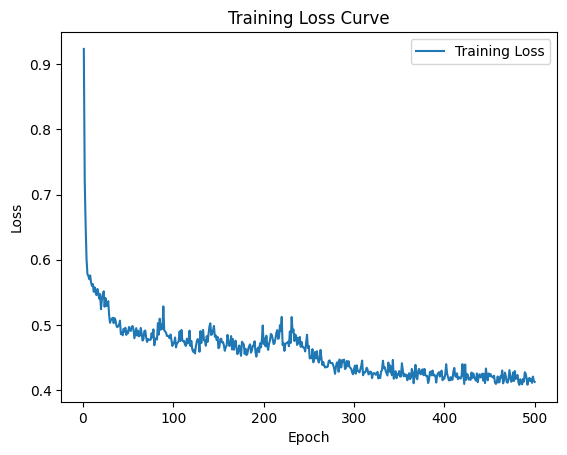

In [250]:
# By using bernoulli model with success probaiblity exp(-||zi-zj||^2), learn embeddings zi for each node i with torch

class Model(torch.nn.Module):
    def __init__(self, nodes_num, in_dim=256, seed:int=0):
        """
        Initialize the VIB model
        """
        super(Model, self).__init__()

        # Set the seed
        random.seed(seed)
        torch.manual_seed(seed)

        # # Set the parameters
        # self.__embs = torch.nn.Parameter(torch.randn(nodes_num, in_dim), requires_grad=True)
        self.m = torch.nn.Parameter(torch.randn(nodes_num, in_dim))
        # self.s_std = torch.nn.Parameter(torch.zeros(nodes_num, in_dim))
        self.s_std = torch.nn.Parameter(
            # torch.randn(nodes_num, in_dim) +
            torch.ones(nodes_num, in_dim)
        )

        #
        # # Define the layers
        # self.linear1_mean = torch.nn.Linear(in_dim, 512, dtype=torch.float)
        # self.batch1_mean = torch.nn.BatchNorm1d(512, dtype=torch.float)
        # self.activation1_mean = torch.nn.Sigmoid()
        # self.dropout1_mean = torch.nn.Dropout(0.2)
        # self.linear2_mean = torch.nn.Linear(512, self.__out_dim, dtype=torch.float)
        #
        # self.linear1_std = torch.nn.Linear(in_dim, 512, dtype=torch.float)
        # self.batch1_std = torch.nn.BatchNorm1d(512, dtype=torch.float)
        # self.activation1_std = torch.nn.Sigmoid()
        # self.dropout1_std = torch.nn.Dropout(0.2)
        # self.linear2_std = torch.nn.Linear(512, self.__out_dim, dtype=torch.float)

        # # Init the std weights of the last layer
        # torch.nn.init.xavier_normal_(self.linear2_std.weight, gain=1e-9)
        # # torch.nn.init.zeros_(self.linear2_std.weight)
        # torch.nn.init.zeros_(self.linear2_std.bias)

    def encoder(self, nodes: torch.Tensor):
        """
        For given kmers, return the mean and std
        """

        # h = self.linear1_mean(embs)
        # h = self.batch1_mean(h)
        # h = self.activation1_mean(h)
        # h = self.dropout1_mean(h)
        # mean = self.linear2_mean(h)
        #
        # h = self.linear1_std(embs)
        # h = self.batch1_std(h)
        # h = self.activation1_std(h)
        # h = self.dropout1_std(h)
        # std = torch.exp(self.linear2_std(h))

        mean = torch.index_select(self.m, 0, nodes)
        # std = torch.exp(torch.index_select(self.s_std, 0, nodes))
        std = torch.index_select(self.s_std, 0, nodes)


        return mean, std

    def forward(self, left_nodes: torch.Tensor, right_nodes:torch.Tensor):
        """
        Forward pass
        """

        left_mean, left_std = self.encoder(left_nodes)
        right_mean, right_std = self.encoder(right_nodes)

        return left_mean, left_std, right_mean, right_std

    def seq2emb(self, nodes:torch.Tensor):
        """
        Get the embeddings for the given nodes
        """

        with torch.no_grad():
            self.eval()
            means, stds = model.encoder(nodes)

        return means.detach().numpy(), stds.detach().numpy()

def log1mexp(x: torch.Tensor):
    """
    Compute `log(1 - exp(-x))` in a numerically stable way for x > 0
    """
    log2 = torch.log(torch.tensor(2.0, dtype=x.dtype, device=x.device))
    return torch.where(
        x < log2, torch.log(-torch.expm1(-x)), torch.log1p(-torch.exp(-x))
    )

def loss_func(left_mean: torch.Tensor, left_std: torch.Tensor, right_mean: torch.Tensor, right_std: torch.Tensor, labels: torch.Tensor):
    """
    Definition of the loss functions
    """

    # Compute the variances
    var_left, var_right = left_std ** 2 + 1e-6, right_std ** 2 + 1e-6

    # Compute the term (m_i - m_j)^2
    mean_squared_diff = (left_mean - right_mean)**2 * (0.5 / (var_left + var_right))

    # Compute the log expectation
    log_expectation = -0.5*(mean_squared_diff).sum(dim=1)
    # # Compute the logits
    # logits = log_expectation - log1mexp(-log_expectation)
    #
    # return torch.mean(
    #     torch.nn.functional.binary_cross_entropy_with_logits(logits, labels, reduction='none'),
    #     dim=0, keepdim=False
    # )
    return torch.nn.functional.binary_cross_entropy(torch.exp(log_expectation),labels,reduction='mean')
    # return -torch.mean(
    #     labels * log_expectation + (1 - labels) * (1 - torch.exp(log_expectation))
    # )

def train_batch(model, criterion, optimizer, left_nodes: torch.Tensor, right_nodes: torch.Tensor, labels: torch.Tensor):
    # Zero your gradients since PyTorch accumulates gradients on subsequent backward passes.
    optimizer.zero_grad()

    # Make predictions for the current epoch
    left_mean, left_std, right_mean, right_std = model(left_nodes, right_nodes)

    # Compute the loss and backpropagate
    batch_loss = criterion(left_mean, left_std, right_mean, right_std, labels)
    batch_loss.backward()

    # Update the model parameters
    optimizer.step()

    return batch_loss

def train_single_epoch(device, model, criterion, optimizer, data_loader):

    epoch_loss = 0.
    for data in data_loader:

        left_nodes, right_nodes, labels = data
        left_nodes = left_nodes.to(device)
        right_nodes = right_nodes.to(device)
        labels = labels.to(device)

        # Run the training for the current batch
        batch_loss = train_batch(
            model=model, criterion=criterion, optimizer=optimizer,
            left_nodes=left_nodes, right_nodes=right_nodes, labels=labels
        )

        # Get the epoch loss for reporting
        epoch_loss += batch_loss

    # Get the average epoch loss
    average_epoch_loss = epoch_loss.item() / len(data_loader)

    return average_epoch_loss

# Train the model
def train(model, loss_func, epoch_num, lr, data_loader, device):

    ### Define the optimizer
    # At the beginning, we will not train the standard deviation parameters so we will not include them in the optimizer
    include_std = False
    model_params = []
    for name, param in model.named_parameters():
        if 'std' in name:
            param.requires_grad = False
        else:
            model_params.append(param)
    ### Define the loss function.
    # Since we won't train the std weights at the beginning, we will not include them in the loss function
    criterion = partial(loss_func)
    # Define the optimizer
    optimizer = torch.optim.Adam(model_params, lr=lr)

    ### Start training
    print(f"+ Training started.")
    # Switch the model to training mode
    model.train()
    loss_list = []

    with tqdm(total=epoch_num) as pbar:
        for current_epoch in range(epoch_num):

            # For the second half of the training, we will also train the std weights
            if current_epoch >= epoch_num * (1./2) and include_std == False:

                # # Set the gradient of the std weights to True
                std_params = []
                for name, param in model.named_parameters():
                    param.requires_grad = False
                    if 'std' in name:
                        param.requires_grad = True
                        std_params.append(param)
                # std_params = model.parameters()
                # Set the include_std to True
                include_std = True
                # Define the optimizer
                optimizer = torch.optim.Adam(std_params, lr=lr/1e2)
                # Define the loss function
                criterion = partial(loss_func)

            ## Run the training for the current epoch
            init_time = time.time()
            loss = train_single_epoch(
                device=device, model=model, criterion=criterion, optimizer=optimizer, data_loader=data_loader
            )
            loss_time = time.time() - init_time
            # print(f"> Epoch {current_epoch+1}/{epoch_num}, Loss: {loss:.4f}, Time: {loss_time:.2f}s")
            pbar.set_description(f"Loss: {loss:.4f}, Time: {loss_time:.2f}s")
            pbar.update(1)
            loss_list.append(loss)

    # Plot the loss curve
    plt.figure()
    plt.plot(range(1, epoch_num + 1), loss_list, label='Training Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training Loss Curve')
    plt.legend()
    plt.show()

# Define parameters
seed = 1
nodes_num = N
in_dim = 2
batch_size = 1024
epoch_num = 500
lr = 1e-1
device = "mps"

####################

# Get all upper triangular indices
all_pairs = torch.triu_indices(N, N, offset=1)
labels = A[all_pairs[0], all_pairs[1]]

# Define the dataset
training_dataset = TensorDataset(
    all_pairs[0], all_pairs[1], torch.tensor(labels, dtype=torch.float)
)

# Define a DataLoader that iterates through batches of data.
training_loader = DataLoader(training_dataset, batch_size=batch_size, num_workers=0,shuffle=True, )

# Define the model
model = Model(nodes_num, in_dim=in_dim, seed=seed)
model.to(device)

### Train the model
train(
    model=model, loss_func=loss_func, epoch_num=epoch_num, lr=lr,  data_loader=training_loader, device=device
)




(208, 2) (208, 2)


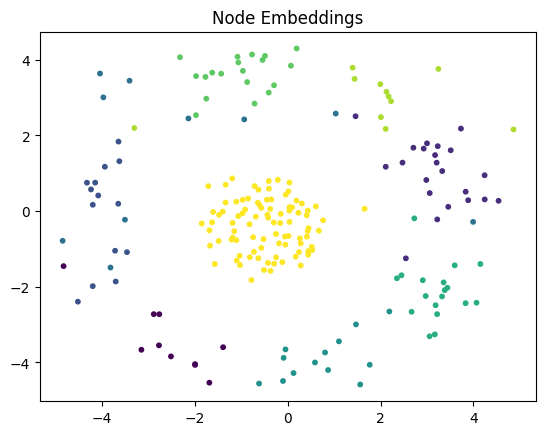

In [251]:
# # Get the embeddings and covariances
model = model.to("cpu")
m, s = model.seq2emb(torch.arange(N))
print(m.shape, s.shape)


# Visualize the embeddings
plt.figure()
plt.scatter(m[:,0], m[:,1], c=np.concatenate([np.full(size, i) for i, size in enumerate(cluster_sizes)]), s=10)
plt.title("Node Embeddings")
plt.show()

L2: AUROC: 0.8261, AUPRC: 0.7061
Mahalanobis: AUROC: 0.8328, AUPRC: 0.6993


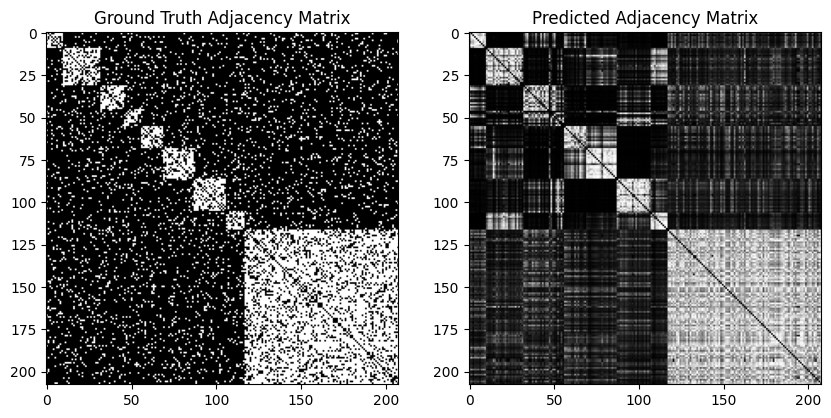

In [252]:
# Make predictions
left_m, right_m = m[all_pairs[0]], m[all_pairs[1]]
left_s, right_s = s[all_pairs[0]]**2, s[all_pairs[1]]**2

mean_squared_diff_without_std = (left_m - right_m)**2
mean_squared_diff_with_std = (left_m - right_m)**2 * (0.5 / (left_s + right_s))
p_without_std = np.exp(-0.5*(mean_squared_diff_without_std).sum(axis=1))
p_with_std = np.exp(-0.5*(mean_squared_diff_with_std).sum(axis=1))

p = p_with_std

P = np.zeros((N, N), dtype=float)
P[all_pairs[0], all_pairs[1]] = p
P = P + P.T

# Compute the AUROC and AUPRC
from sklearn.metrics import roc_auc_score, average_precision_score
auroc = roc_auc_score(labels, p_without_std)
auprc = average_precision_score(labels, p_without_std)
print(f"L2: AUROC: {auroc:.4f}, AUPRC: {auprc:.4f}")
auroc = roc_auc_score(labels, p_with_std)
auprc = average_precision_score(labels, p_with_std)
print(f"Mahalanobis: AUROC: {auroc:.4f}, AUPRC: {auprc:.4f}")

# Plot the ground truth and predicted adjacency matrices side by side
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(A, cmap='gray')
axs[0].set_title('Ground Truth Adjacency Matrix')
axs[1].imshow(P, cmap='gray')
axs[1].set_title('Predicted Adjacency Matrix')
plt.show()


(416,)


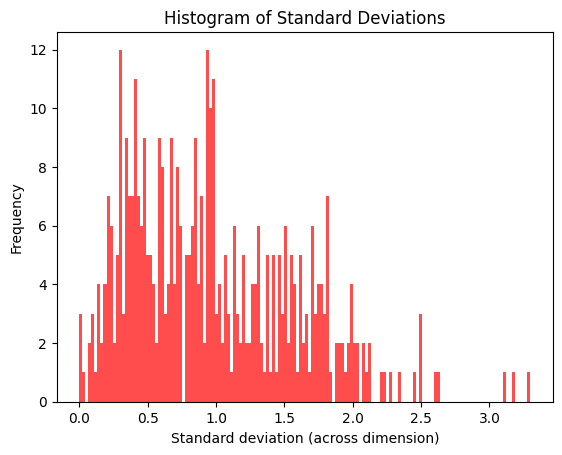

In [249]:
# Plot the histogram of the variances
variances = s.flatten()**2
print(variances.shape)
plt.figure()
plt.hist(variances, bins=150, color='red', alpha=0.7)
plt.title("Histogram of Standard Deviations")
plt.xlabel("Standard deviation (across dimension)")
plt.ylabel("Frequency")
plt.show()

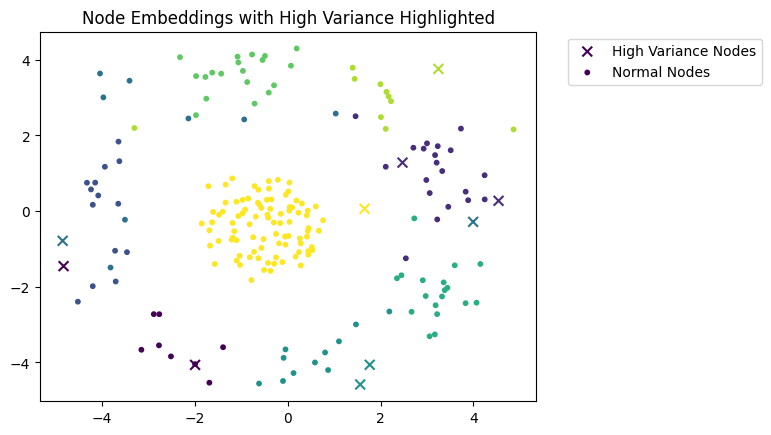

In [255]:
# Plot the embedings again and mark the nodes with high variance
is_high_var_node = (s**2).max(axis=1) > 2.5
colors = np.concatenate([np.full(size, i) for i, size in enumerate(cluster_sizes)])
plt.figure()
plt.scatter(m[is_high_var_node,0], m[is_high_var_node,1], c=colors[is_high_var_node], s=50, marker='x', label='High Variance Nodes')
plt.scatter(m[~is_high_var_node,0], m[~is_high_var_node,1], c=colors[~is_high_var_node], s=10, label='Normal Nodes')
plt.title("Node Embeddings with High Variance Highlighted")
plt.legend()
# Position the legend outside the plot
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

In [246]:
def get_clusters_of_node(idx, adj, cluster_sizes):
    assert len(idx) > 1, "idx should contain more than one node"

    cluster_cum_sizes = np.cumsum(np.concat((np.zeros(shape=(1,)), cluster_sizes))).astype(int)
    adj_cum_sum = np.hstack((np.zeros((len(idx),1)), np.cumsum(adj[idx, :], axis=1)))

    cluster_membership_weight = (adj_cum_sum[:, cluster_cum_sizes][:, 1:] - adj_cum_sum[:, cluster_cum_sizes][:, :-1]) / cluster_sizes[None, :]

    return cluster_membership_weight

high_var_node_idx = np.where(is_high_var_node)[0]
print(f"High variance nodes: {high_var_node_idx}")
memberships = get_clusters_of_node(idx=high_var_node_idx, adj=A, cluster_sizes=np.asarray(cluster_sizes))
# print(memberships)
threshold = 0.15
print((memberships > threshold).sum(axis=1))

normal_node_memberships = get_clusters_of_node(idx=np.asarray([0, 11,23, 19]), adj=A, cluster_sizes=np.asarray(cluster_sizes))
print((normal_node_memberships > threshold).sum(axis=1))

High variance nodes: []


AssertionError: idx should contain more than one node